# 10 — exp0: verification on known-truth surfaces shaped like exp1

goldstein36_graded, goldstein36_flip and himmelblau36_graded: 3 continuous variables, levels (4, 3, 3) = 36 categories, 1 initial sample per category, 250 samples with no early stopping, 10 seeds; the same active loop as the CNS campaigns. Runs are cached in `results/exp0_runs_full.pkl`; tables and curves are also written as CSV.

In [1]:
import pickle
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mvlse import run_lse, score_level_set
from mvlse.benchmark import test_grid
from mvlse.problems import get_problem

sys.path.insert(0, str(Path.cwd().parent))
import common
import config

P = config.EXPERIMENTS["exp0_verify"]
CACHE = Path("results/exp0_runs_full.pkl")   # one entry per (problem, method, seed); reruns skip done runs
print(P)
print(common.code_state())

{'problems': ['goldstein36_graded', 'goldstein36_flip', 'himmelblau36_graded'], 'methods': ['category_wise', 'dc', 'gower', 'hs_dim'], 'seeds': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], 'max_evaluations': 250, 'n_init_per_category': 1}
{'mvlse': {'commit': 'cbfd09ffc17a4e6b90ea5882e76d1ff932df5a3f', 'dirty': False}, 'blueskycdarr': {'commit': '030c0f459a3c5491cef88485e2672aef60a14179', 'dirty': False}}


In [2]:
# Every (problem, method, seed), as the campaigns run (no early stopping), in parallel, cached per run.
import os
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"          # one BLAS thread per worker: the workers are the parallelism
os.environ["OMP_NUM_THREADS"] = "1"
from joblib import Parallel, delayed

N_WORKERS = 6
COST = {"hs_dim": 4, "gower": 2, "dc": 2, "category_wise": 1}   # rough run time, to start the long ones first


def one_run(name, method, seed, stop):
    prob = get_problem(name)
    grid = test_grid(prob)
    truth = prob.truth(grid)
    t0 = time.perf_counter()
    res = run_lse(prob.space, prob, threshold=prob.threshold, method=method, seed=seed,
                  max_evaluations=P["max_evaluations"], n_init_per_category=P["n_init_per_category"],
                  flip_tolerance=config.LSE["flip_tolerance"], stop_when_confident=stop,
                  monitor=grid, keep_snapshots=True, verbose=False)
    scores = [score_level_set(mu, truth, prob.threshold) for mu, _ in res.snapshots]
    return (name, method, seed), {
        "n": [r.n_evaluations for r in res.rounds],
        "max_straddle": [r.max_straddle for r in res.rounds],
        "f1": [s.f1 for s in scores],
        "accuracy": [s.accuracy for s in scores],
        "stop": res.stop_reason, "n_final": res.n_evaluations,
        "confident": res.stop_reason.startswith("confident"),
        "seconds": time.perf_counter() - t0,
        "n_hyperparameters": getattr(res.model, "n_hyperparameters", np.nan),
        "level_correlations": res.level_correlations(),
        "w": res.w, "y": res.y,
    }


def run_all(jobs, cache, stop):
    done = pickle.loads(cache.read_bytes()) if cache.exists() else {}
    todo = sorted((j for j in jobs if j not in done), key=lambda j: (-COST[j[1]], "himmelblau" not in j[0]))
    print(f"{len(jobs) - len(todo)} of {len(jobs)} runs cached, {len(todo)} to run", flush=True)
    t0 = time.perf_counter()
    for key, rec in Parallel(n_jobs=N_WORKERS, return_as="generator_unordered")(
            delayed(one_run)(*j, stop) for j in todo):
        done[key] = rec
        cache.write_bytes(pickle.dumps(done))
        print(f"[{(time.perf_counter() - t0) / 60:5.1f} min] {key[0]:20s} {key[1]:14s} seed {key[2]:2d}: "
              f"n={rec['n_final']:3d} F1={rec['f1'][-1]:.4f} {rec['stop'][:9]} [{rec['seconds'] / 60:.1f} min]", flush=True)
    return done


runs = run_all([(n, m, s) for n in P["problems"] for m in P["methods"] for s in P["seeds"]], CACHE,
               stop=config.LSE["stop_when_confident"])

# Per-round curves of every run, readable without Python.
pd.DataFrame([{"problem": k[0], "method": k[1], "seed": k[2], "n_samples": n, "f1": f, "accuracy": a}
              for k, r in runs.items() for n, f, a in zip(r["n"], r["f1"], r["accuracy"])]
             ).to_csv("results/exp0_curves.csv", index=False)
pd.DataFrame([{"problem": k[0], "method": k[1], "seed": k[2], "n_final": r["n_final"], "stop": r["stop"],
               "confident": r["confident"], "final_f1": r["f1"][-1], "final_accuracy": r["accuracy"][-1],
               "seconds": r["seconds"], "n_hyperparameters": r["n_hyperparameters"]}
              for k, r in runs.items()]).to_csv("results/exp0_runs.csv", index=False)
print("wrote results/exp0_curves.csv and results/exp0_runs.csv")

120 of 120 runs cached, 0 to run


wrote results/exp0_curves.csv and results/exp0_runs.csv


In [3]:
# Per problem and method (mean +- sd over seeds): F1 at 100 and at 250 samples, the samples
# needed to reach F1 >= 0.99 (Bryan et al. 2005 style, needs the truth), and where the max
# straddle first dropped below 0 (where a confident stop would have fired; diagnostic only).
def first_n(r, ok):
    hits = [n for n, v in zip(r["n"], ok) if v]
    return hits[0] if hits else np.nan

def mean_sd(v, fmt):
    v = np.asarray(v, float)
    hit = v[~np.isnan(v)]
    if len(hit) == 0:
        return "never"
    s = f"{fmt.format(hit.mean())} +- {fmt.format(hit.std())}"
    return s if len(hit) == len(v) else s + f" ({len(hit)}/{len(v)} runs)"

rows = []
for name in P["problems"]:
    for method in P["methods"]:
        rs = [runs[name, method, s] for s in P["seeds"]]
        f1_100 = [np.interp(100, r["n"], r["f1"]) for r in rs]
        rows.append({
            "problem": name, "method": method, "hyperparameters": rs[0]["n_hyperparameters"],
            "F1 at 100": mean_sd(f1_100, "{:.4f}"),
            "F1 at 250": mean_sd([r["f1"][-1] for r in rs], "{:.4f}"),
            "samples to F1 >= 0.99": mean_sd([first_n(r, np.array(r["f1"]) >= 0.99) for r in rs], "{:.0f}"),
            "max straddle < 0 first at": mean_sd([first_n(r, np.array(r["max_straddle"]) < 0) if "max_straddle" in r
                                                  else np.nan for r in rs], "{:.0f}"),
            "accuracy at 250": f"{np.mean([r['accuracy'][-1] for r in rs]):.2%}",
            "minutes per run": f"{np.mean([r['seconds'] for r in rs]) / 60:.1f}",
        })
table = pd.DataFrame(rows).set_index(["problem", "method"])
table.to_csv("results/exp0_summary.csv")
table

hyperparameters         F1 at 100  \
problem             method                                             
goldstein36_graded  category_wise              108  0.6782 +- 0.0656   
                    dc                           6  0.9952 +- 0.0006   
                    gower                        6  0.9928 +- 0.0007   
                    hs_dim                      15  0.9984 +- 0.0004   
goldstein36_flip    category_wise              108  0.7135 +- 0.0204   
                    dc                           6  0.9965 +- 0.0006   
                    gower                        6  0.9915 +- 0.0014   
                    hs_dim                      15  0.9992 +- 0.0002   
himmelblau36_graded category_wise              108  0.0226 +- 0.0196   
                    dc                           6  0.4223 +- 0.0999   
                    gower                        6  0.4904 +- 0.0494   
                    hs_dim                      15  0.5174 +- 0.0547   

                                          F1 at 250 samples to F1 >= 0.99  \
problem             method                                                  
goldstein36_graded  category_wise  0.8218 +- 0.0205                 never   
                    dc             0.9997 +- 0.0001               67 +- 6   
                    gower          0.9995 +- 0.0001               81 +- 6   
                    hs_dim         0.9998 +- 0.0001               56 +- 6   
goldstein36_flip    category_wise  0.8112 +- 0.0214                 never   
                    dc             0.9996 +- 0.0002               60 +- 7   
                    gower          0.9992 +- 0.0003               89 +- 8   
                    hs_dim         0.9999 +- 0.0001               42 +- 4   
himmelblau36_graded category_wise  0.0791 +- 0.0121                 never   
                    dc             0.7050 +- 0.0617                 never   
                    gower          0.8112 +- 0.0424                 never   
                    hs_dim         0.8825 +- 0.0256                 never   

                                  max straddle < 0 first at accuracy at 250  \
problem             method                                                    
goldstein36_graded  category_wise                     never          77.99%   
                    dc                             168 +- 4          99.96%   
                    gower                          191 +- 4          99.95%   
                    hs_dim                         126 +- 2          99.98%   
goldstein36_flip    category_wise     234 +- 13 (2/10 runs)          77.86%   
                    dc                             153 +- 7          99.95%   
                    gower                          211 +- 9          99.91%   
                    hs_dim                         106 +- 7          99.99%   
himmelblau36_graded category_wise                     never          93.52%   
                    dc                                never          96.86%   
                    gower                             never          98.01%   
                    hs_dim                            never          98.71%   

                                  minutes per run  
problem             method                         
goldstein36_graded  category_wise             1.6  
                    dc                       12.7  
                    gower                    16.9  
                    hs_dim                   79.5  
goldstein36_flip    category_wise             1.4  
                    dc                       13.1  
                    gower                    14.7  
                    hs_dim                   84.1  
himmelblau36_graded category_wise             1.6  
                    dc                        8.1  
                    gower                     9.0  
                    hs_dim                   56.3

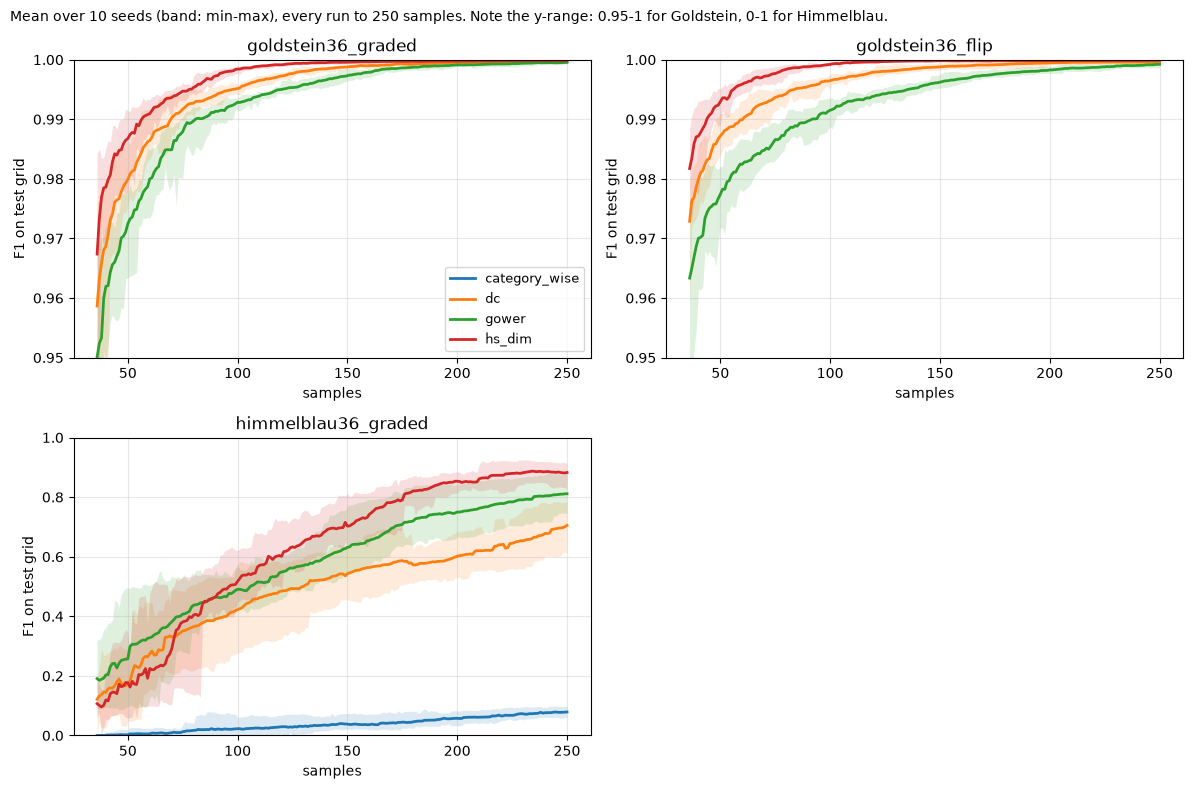

In [4]:
# F1 against samples, linear axis. Methods differ only by colour (matplotlib defaults C0-C3).
def curve(r, n_axis):
    return np.interp(n_axis, r["n"], r["f1"], right=r["f1"][-1])

n_axis = np.arange(P["n_init_per_category"] * 36, P["max_evaluations"] + 1)
colors = {m: f"C{i}" for i, m in enumerate(P["methods"])}
ylim = {"goldstein": (0.95, 1.0), "himmelblau": (0.0, 1.0)}      # per function: Goldstein converges near 1
ncol = 2
nrow = int(np.ceil(len(P["problems"]) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 4.0 * nrow), squeeze=False)
for ax, name in zip(axes.flat, P["problems"]):
    for method in P["methods"]:
        c = np.array([curve(runs[name, method, s], n_axis) for s in P["seeds"]])
        ax.plot(n_axis, c.mean(axis=0), color=colors[method], lw=2, label=method)
        ax.fill_between(n_axis, c.min(axis=0), c.max(axis=0), color=colors[method], alpha=0.15, lw=0)
        stops = [runs[name, method, s]["n_final"] for s in P["seeds"] if runs[name, method, s]["confident"]]
        if stops:
            ax.axvline(np.mean(stops), color=colors[method], lw=1, ls=":")
    ax.set_ylim(*ylim[name.split("36")[0]])
    ax.set_title(name); ax.set_xlabel("samples"); ax.set_ylabel("F1 on test grid"); ax.grid(alpha=0.3)
for ax in axes.flat[len(P["problems"]):]:
    ax.remove()
axes.flat[0].legend(fontsize=9, loc="lower right")
fig.suptitle("Mean over 10 seeds (band: min-max), every run to 250 samples. "
             "Note the y-range: 0.95-1 for Goldstein, 0-1 for Himmelblau.", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.savefig("results/exp0_f1_vs_samples.pdf")
plt.show()

In [5]:
# What each method learned about the levels of C (seed 1), against the true correlation of the
# response across those levels on the test grid.
corr_rows = []
for name in P["problems"]:
    prob = get_problem(name)
    grid = test_grid(prob)
    c_col = prob.space.names.index("C")
    base = grid[grid[:, c_col] == 0]
    true = np.corrcoef([prob.truth(np.column_stack([base[:, :c_col], np.full(len(base), k)])) for k in range(3)])
    out = {"truth": true[np.triu_indices(3, 1)]}
    for method in ("dc", "gower", "hs_dim"):
        lc = runs[name, method, 1]["level_correlations"].get("C")
        out[method] = lc[np.triu_indices(3, 1)]
    corr_rows += [{"problem": name, "pair": pr, **{k: v[j] for k, v in out.items()}} for j, pr in enumerate(["A-B", "A-C", "B-C"])]
    print(name)
    print(pd.DataFrame(out, index=["A-B", "A-C", "B-C"]).round(3), "\n")
pd.DataFrame(corr_rows).to_csv("results/exp0_level_correlations.csv", index=False)

goldstein36_graded
     truth     dc  gower  hs_dim
A-B  0.158  0.647  0.959   0.907
A-C  0.997  0.176  0.959   0.999
B-C  0.082  0.647  0.959   0.884 



goldstein36_flip
     truth   dc  gower  hs_dim
A-B   -1.0  0.0    0.0  -0.970
A-C    1.0  0.0    0.0   0.984
B-C   -1.0  0.0    0.0  -0.911 

himmelblau36_graded
     truth     dc  gower  hs_dim
A-B  0.867  0.867  0.959   0.965
A-C  0.973  0.564  0.959   0.997
B-C  0.731  0.867  0.959   0.942 



In [6]:
# Estimated surface vs truth (seed 1). The final samples of each run are cached in
# results/exp0_final_samples.pkl; the model is refitted once from them.
from mvlse import fit_surrogate

FINAL = Path("results/exp0_final_samples.pkl")
final = pickle.loads(FINAL.read_bytes()) if FINAL.exists() else {}
for name in P["problems"]:
    prob = get_problem(name)
    for method in P["methods"]:
        if "w" in runs[name, method, 1]:                        # the main loop kept them
            final[name, method] = {"w": runs[name, method, 1]["w"], "y": runs[name, method, 1]["y"]}
        elif (name, method) not in final:                       # run cached before samples were kept
            res = run_lse(prob.space, prob, threshold=prob.threshold, method=method, seed=1,
                          max_evaluations=P["max_evaluations"], n_init_per_category=P["n_init_per_category"],
                          flip_tolerance=config.LSE["flip_tolerance"], verbose=False)
            final[name, method] = {"w": res.w, "y": res.y}
            FINAL.write_bytes(pickle.dumps(final))
models = {key: fit_surrogate(key[1], get_problem(key[0]).space, v["w"], v["y"], rng=np.random.default_rng(0))
          for key, v in final.items()}
print({k: len(v["w"]) for k, v in final.items()})

pd.concat([pd.DataFrame([dict(p) for p in get_problem(k[0]).space.decode(v["w"])]).assign(problem=k[0], method=k[1], seed=1, response=v["y"])
           for k, v in final.items()]).to_csv("results/exp0_final_samples.csv", index=False)
print("wrote results/exp0_final_samples.csv")

{('goldstein36_graded', 'category_wise'): 250, ('goldstein36_graded', 'dc'): 250, ('goldstein36_graded', 'gower'): 250, ('goldstein36_graded', 'hs_dim'): 250, ('goldstein36_flip', 'category_wise'): 250, ('goldstein36_flip', 'dc'): 250, ('goldstein36_flip', 'gower'): 250, ('goldstein36_flip', 'hs_dim'): 250, ('himmelblau36_graded', 'category_wise'): 250, ('himmelblau36_graded', 'dc'): 250, ('himmelblau36_graded', 'gower'): 250, ('himmelblau36_graded', 'hs_dim'): 250}


wrote results/exp0_final_samples.csv


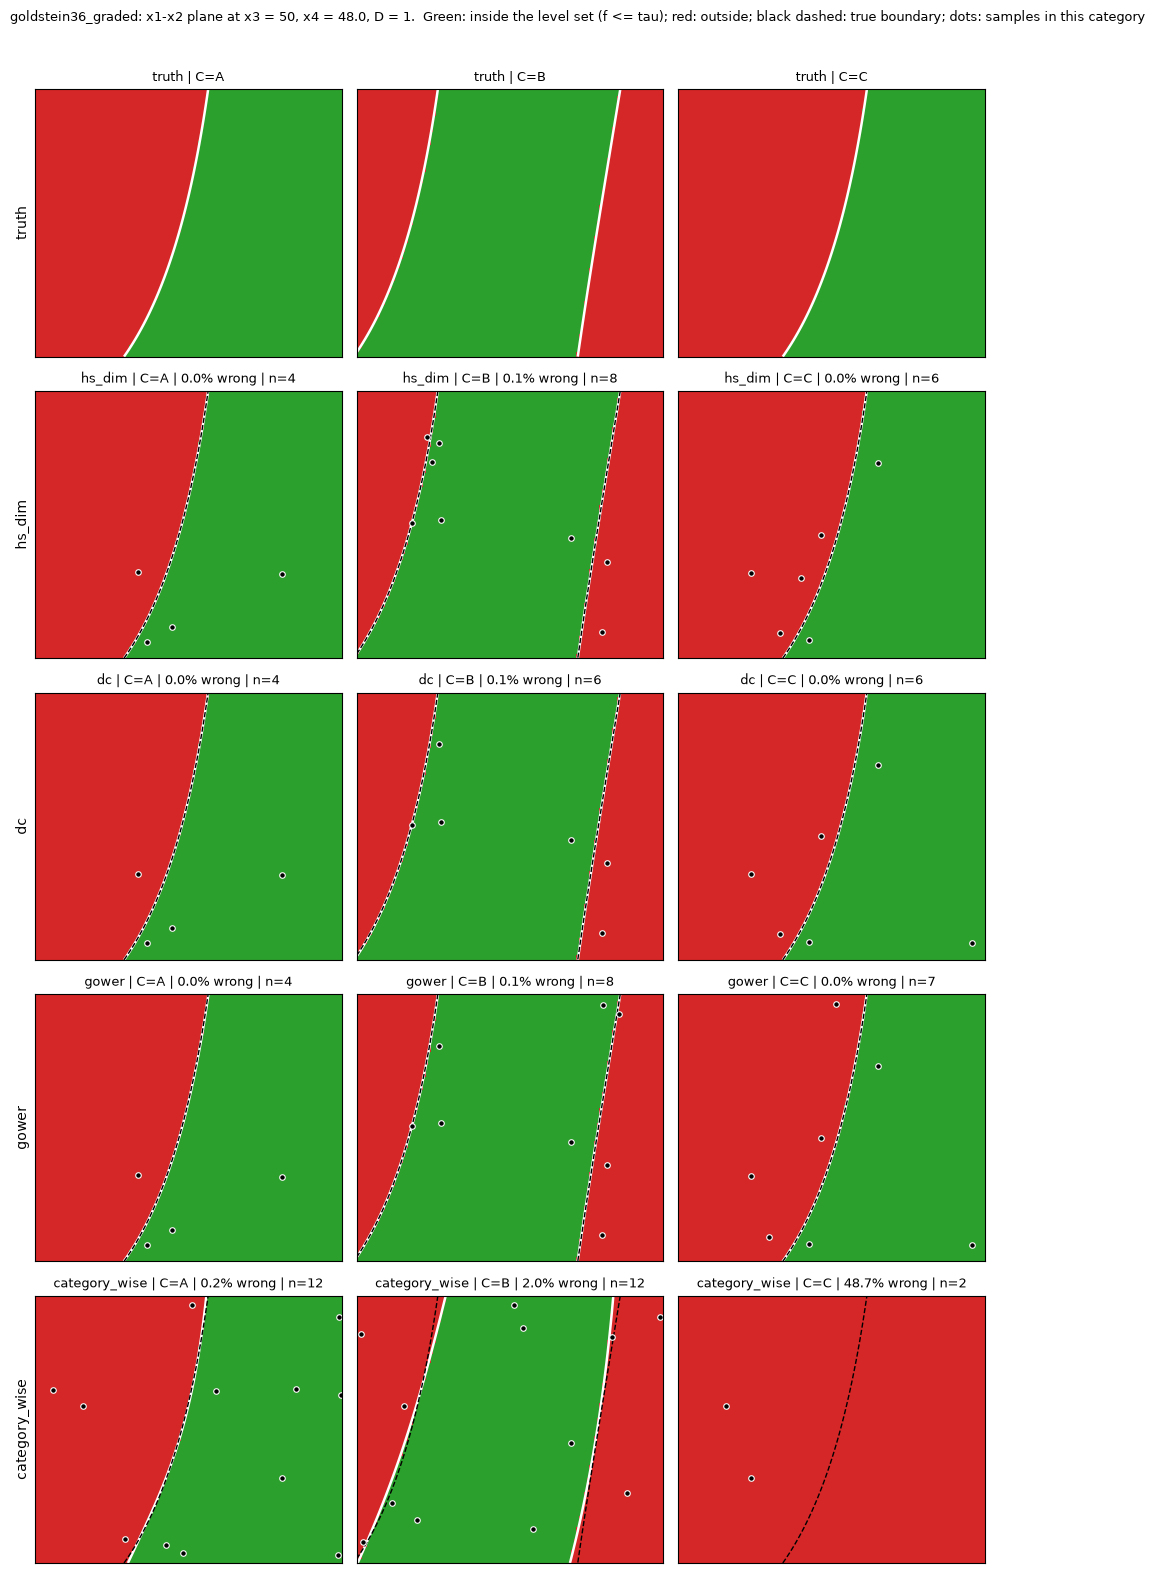

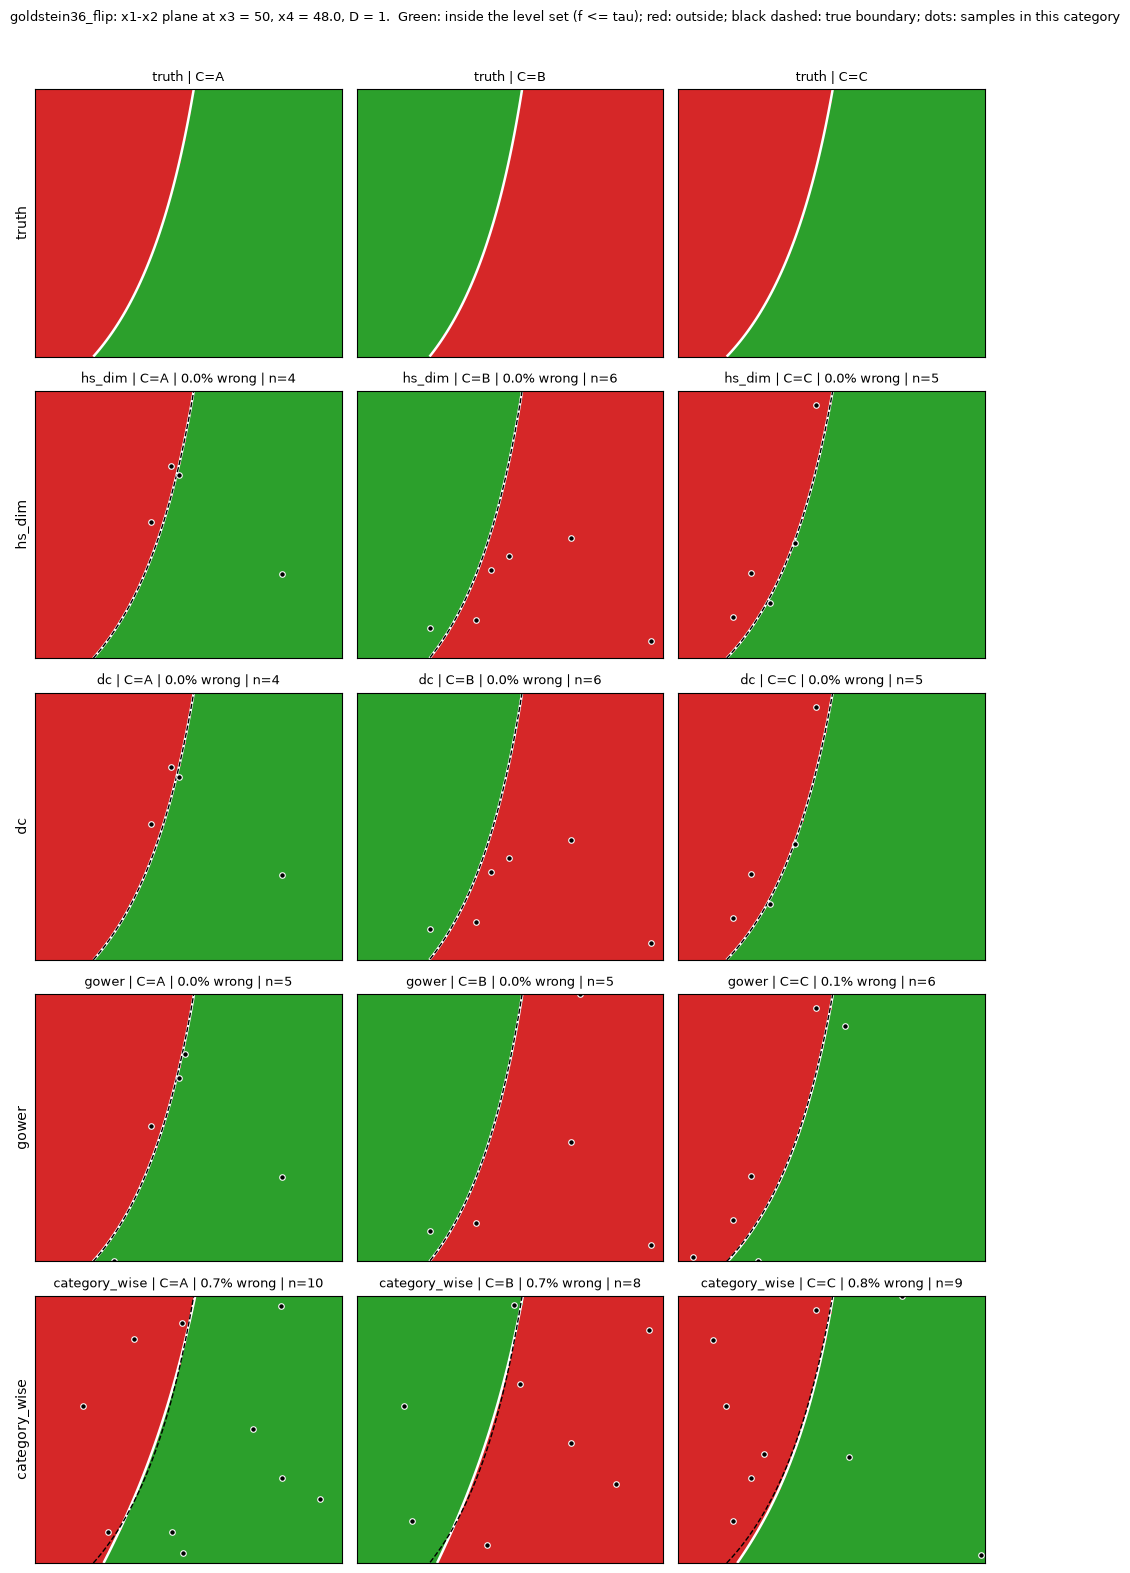

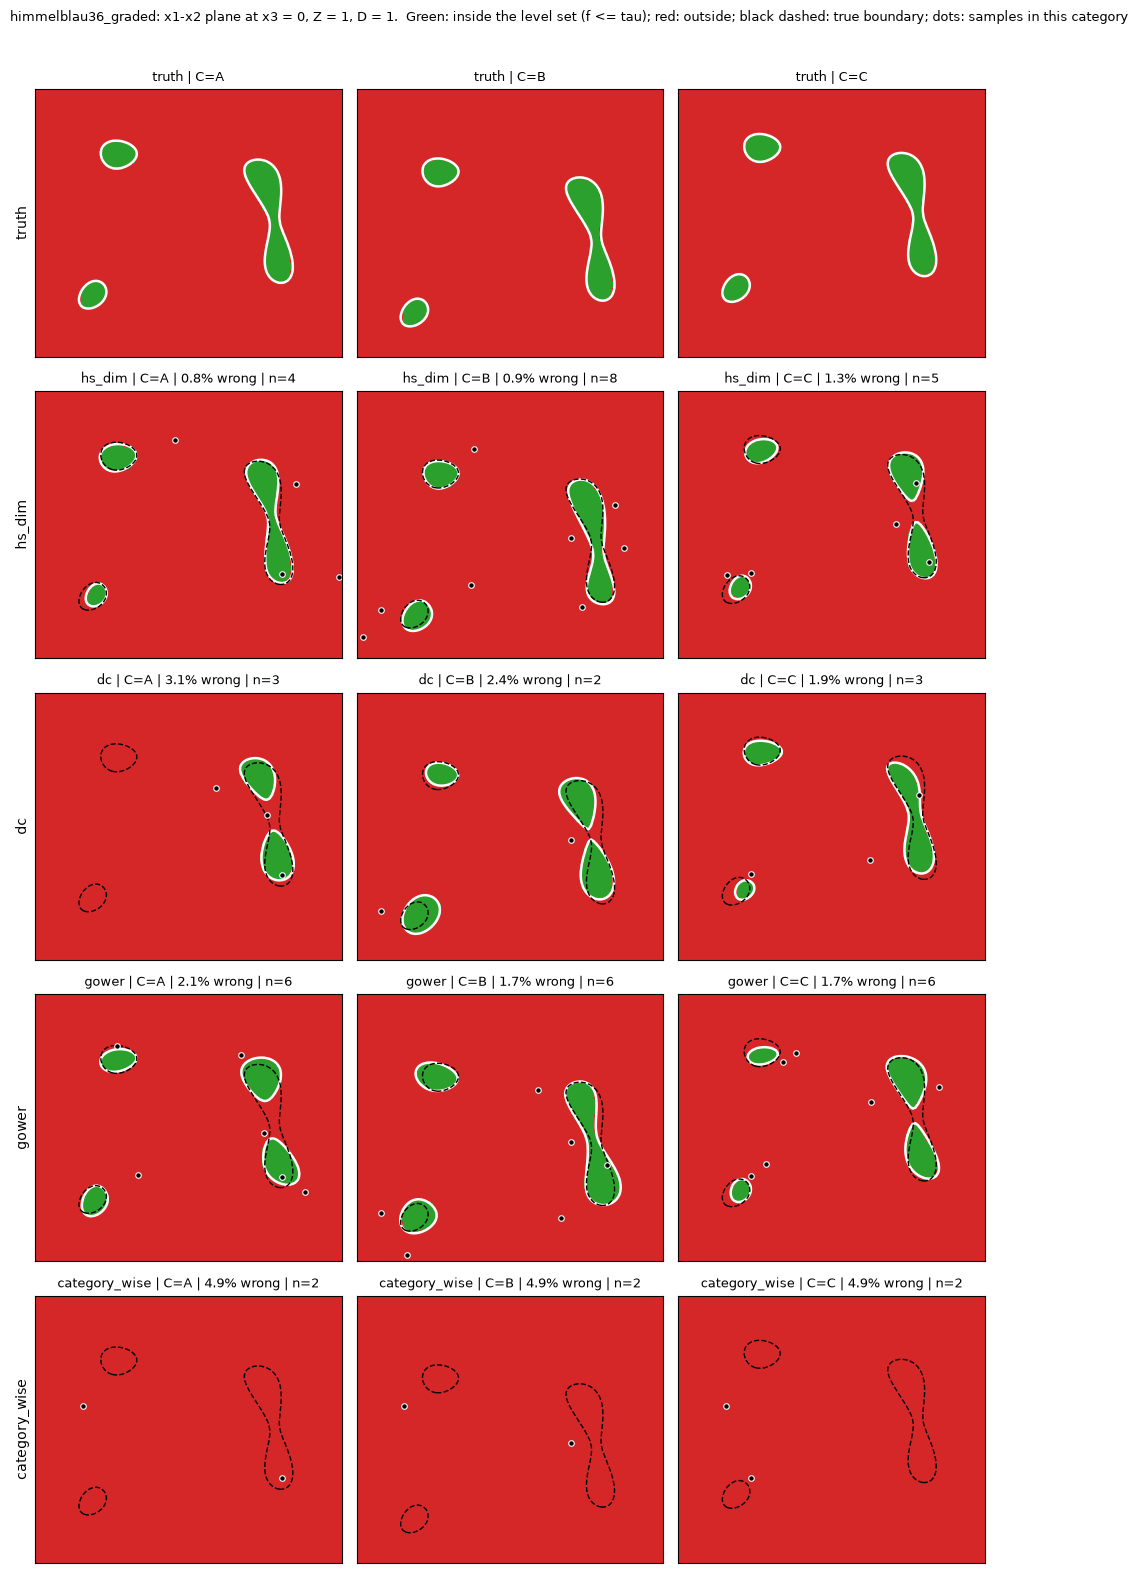

In [7]:
# Estimated surface vs truth on a 2-D slice of each problem: the first two continuous
# variables on the axes, the third at mid-range, the first two discrete variables at
# level 1, one column per level of C. Two colours: green inside the level set (f <= tau, the
# acceptable side), red outside; white line: boundary of the map shown; black dashed: true boundary; dots: samples.

from matplotlib.colors import ListedColormap

TWO = ListedColormap(["tab:red", "tab:green"])        # 0 = outside (red), 1 = inside the level set (green)
N = 120
order = ["truth", "hs_dim", "dc", "gower", "category_wise"]
for name in P["problems"]:
    prob = get_problem(name)
    sp = prob.space
    xa, xb, xc = sp.continuous_names
    d1, d2, dc_ = sp.discrete_names
    (a_lo, a_hi), (b_lo, b_hi) = sp.continuous_bounds[0], sp.continuous_bounds[1]
    g1, g2 = np.meshgrid(np.linspace(0, 1, N), np.linspace(0, 1, N))
    pa, pb = a_lo + g1 * (a_hi - a_lo), b_lo + g2 * (b_hi - b_lo)
    fields = {}
    for k in range(3):
        w = np.column_stack([g1.ravel(), g2.ravel(), np.full(N * N, 0.5),
                             np.full(N * N, 1), np.full(N * N, 1), np.full(N * N, k)])
        fields["truth", k] = prob.truth(w)
        for method in order[1:]:
            fields[method, k] = models[name, method].predict(w)[0]

    fig, axes = plt.subplots(len(order), 3, figsize=(10, 3.2 * len(order)), sharex=True, sharey=True)
    for i, method in enumerate(order):
        for k, level in enumerate(sp.variable(dc_).levels):
            ax = axes[i, k]
            f = fields[method, k].reshape(N, N)
            inside = (f <= prob.threshold).astype(float)
            ax.imshow(inside, origin="lower", extent=(a_lo, a_hi, b_lo, b_hi), cmap=TWO, vmin=0, vmax=1,
                      aspect="auto", interpolation="nearest")
            ax.contour(pa, pb, f, levels=[prob.threshold], colors="white", linewidths=1.8)
            if method != "truth":
                ax.contour(pa, pb, fields["truth", k].reshape(N, N), levels=[prob.threshold],
                           colors="black", linewidths=1.0, linestyles="--")
                wrong = np.mean((fields[method, k] <= prob.threshold) != (fields["truth", k] <= prob.threshold))
                w_s = final[name, method]["w"]
                cat = (w_s[:, 3] == 1) & (w_s[:, 4] == 1) & (w_s[:, 5] == k)
                ax.plot(a_lo + w_s[cat, 0] * (a_hi - a_lo), b_lo + w_s[cat, 1] * (b_hi - b_lo), "o",
                        ms=4, mfc="black", mec="white", mew=0.8)
                ax.set_title(f"{method} | {dc_}={level} | {wrong:.1%} wrong | n={cat.sum()}", fontsize=9)
            else:
                ax.set_title(f"truth | {dc_}={level}", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
            if k == 0:
                ax.set_ylabel(method if i else "truth")
    mid = sp.variable(xc).from_unit(np.array(0.5))
    fig.suptitle(f"{name}: {xa}-{xb} plane at {xc} = {float(mid):g}, {d1} = {sp.variable(d1).levels[1]}, "
                 f"{d2} = {sp.variable(d2).levels[1]}.  Green: inside the level set (f <= tau); red: outside; "
                 "black dashed: true boundary; dots: samples in this category",
                 x=0.01, ha="left", fontsize=9)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


## Draft text for Sec. 4.6

*Numbers from this notebook (10 seeds, every run to 250 samples, no early stopping); tables in
`results/exp0_summary.csv`, figure `results/exp0_f1_vs_samples.pdf`.*

---

**4.6 Analytical test-cases: verification on a known level set**

Before the method is applied to the CNS problem, where the boundary is unknown, it is
verified on analytical test-cases whose level set is known exactly. Three test-cases are
built with the same structure as the heading scan of Section 5: three continuous variables
and three discrete variables with four, three and three levels, i.e. 36 categories. Two are
based on the Goldstein function \citep{pelamatti_overview_2020}, whose level set is bounded by
one smooth curve in every category. In the *graded* variant the levels of the third discrete
variable are positively correlated; in the *flipped* variant one level is the mirror image of
the other two, so that categories are negatively correlated. The third is based on
Himmelblau's function \citep{moss_bayesian_2023}, whose level set consists of several small,
disjoint regions with steep walls in every category. The active loop is run as in the CNS
campaigns: one initial sample per category, the straddle acquisition, and 250 samples with no
early stopping. Each test-case is repeated with ten seeds, as in
\citet{pelamatti_overview_2020}, for four surrogate models: category-wise Kriging, direct
conversion, the Gower distance and the dimension-wise hypersphere decomposition. The
classification is scored by the F1 score on 18,432 unmapped points.

The dimension-wise hypersphere decomposition locates the boundary with the fewest samples on
every test-case (Fig. X, Table Y). On the Goldstein test-cases all three models with a shared
correlation structure end above F1 = 0.999 after 250 samples, so the final accuracy does not
separate them; the number of samples needed does. The hypersphere decomposition reaches
F1 = 0.99 after 56 ± 6 samples on the graded variant and 42 ± 4 on the flipped one, against
67 ± 6 and 60 ± 7 for direct conversion and 81 ± 6 and 89 ± 8 for the Gower distance. On the
Himmelblau test-case no model reaches F1 = 0.99 within 250 samples, because several narrow
regions must be located in every category, and the final accuracy separates the models:
F1 = 0.88 ± 0.03 for the hypersphere decomposition against 0.81 ± 0.04 for the Gower distance
and 0.71 ± 0.06 for direct conversion.

The advantage comes from the correlation between levels. On the flipped test-case the
hypersphere decomposition recovers the sign structure of the discrete variable that carries the
flip: the fitted correlations between its levels are −0.97, +0.98 and −0.91, against true
values of −1, +1 and −1. Direct conversion and the Gower distance cannot represent a negative
correlation (Section~\ref{sec:mixed-gp}) and settle at zero, treating the levels as
unrelated; each category must then be learned from its own samples. Category-wise Kriging,
which shares no information between categories, fails on every test-case (F1 = 0.82, 0.81 and
0.08 after 250 samples): with one initial sample in each of 36 categories, too few samples
reach each category for it to fit.

The verification supports two design choices for the CNS campaigns: a single surrogate model
across all categories, with the dimension-wise hypersphere decomposition as its correlation
structure for the discrete variables. It also shows the limit of a fixed number of samples: a
level set made of several disjoint regions is not fully resolved within 250 samples even by the
best model, which is why every CNS run reports its final maximum straddle
(Section~\ref{sec:acquisition}).

---

*Notes for the author (not for the paper):*
- *Section number: your outline puts the analytical test-cases in Sec. 4.6 (`\label{sec:toy}`),
  not 5.4; the heading above follows the outline.*
- *Where a confident stop would have fired (diagnostic column of the table): Goldstein 106–211
  samples, by which point every shared-correlation model was already above F1 = 0.998;
  Himmelblau never. Not in the text, since no stop is used; useful if a reviewer asks.*
- *Graded test-cases: GP level correlations are not Pearson correlations of the raw response, so
  only the flipped test-case is quoted.*
- *Himmelblau's set covers 6% of the domain: accuracy is 94–99% for every model while F1 is
  0.08–0.88. F1 is the right measure.*
- *Wall-clock times in the table are with 6 runs in parallel, so they overstate a single run.*
